# AI 응용 학습 (AI Native Master) - M1-1
## 원/달러(USD/KRW) 환율 트렌드 및 거시경제 충격 분석
본 노트북은 2023~2024년 원/달러 일별 환율(`KRW=X`) 시계열 데이터를 바탕으로 데이터 수집, 결측치/이상치 정제, 이동평균선(20/60일), 월별 변동성, 시계열 가법 분해 및 단기 베이스라인 예측을 단계별로 수행합니다.

In [1]:
# STEP 0: 환경 설정 및 라이브러리 임포트
import os
import sys
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose

os.makedirs("data", exist_ok=True)
os.makedirs("images", exist_ok=True)

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="Malgun Gothic")
print("환경 세팅 완료!")

환경 세팅 완료!


In [2]:
# STEP 1: Yahoo Finance 원/달러 환율 데이터 수집 및 결측치 검증
ticker = "KRW=X"
start_date = "2023-01-01"
end_date = "2024-12-31"

df = yf.download(ticker, start=start_date, end=end_date)
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df.index = pd.to_datetime(df.index)
df = df.sort_index()
df = df.ffill().bfill()

df.to_csv("data/usdkrw_2023_2024.csv", encoding="utf-8-sig")
print(f"데이터 수집 완료: 총 {len(df)}개 거래일 데이터 확보")
df.head()

데이터 수집 완료: 총 521개 거래일 데이터 확보


Price,Close,High,Low,Open,Volume
Date,,,,,
2023-01-02,1260.910034,1273.930054,1256.550049,1260.910034,0
2023-01-03,1270.099976,1278.969971,1264.390015,1270.099976,0
2023-01-04,1279.079956,1279.719971,1267.560059,1279.079956,0
2023-01-05,1271.079956,1278.229980,1265.739990,1271.079956,0
2023-01-06,1274.180054,1274.180054,1253.010010,1274.180054,0


In [3]:
# STEP 2: 시계열 피처 엔지니어링 및 거시 충격 이상치 탐색
df["SMA_20"] = df["Close"].rolling(window=20).mean()
df["SMA_60"] = df["Close"].rolling(window=60).mean()
df["Daily_Return"] = df["Close"].pct_change() * 100
df["Volatility_20"] = df["Daily_Return"].rolling(window=20).std()
df["Year_Month"] = df.index.to_period("M")
df["Shock_Flag"] = df["Daily_Return"].abs() >= 1.5

df.to_csv("data/usdkrw_processed.csv", encoding="utf-8-sig")
print("이상치 탐지 결과 (절댓값 1.5% 이상):", df["Shock_Flag"].sum(), "일")
df[["Close", "SMA_20", "SMA_60", "Daily_Return", "Volatility_20"]].tail()

이상치 탐지 결과 (절댓값 1.5% 이상): 11 일


Price,Close,SMA_20,SMA_60,Daily_Return,Volatility_20
Date,,,,,
2024-12-24,1442.699951,1421.074500,1389.814001,-0.188187,0.622537
2024-12-25,1453.420044,1423.982001,1391.957003,0.743058,0.633672
2024-12-26,1457.609985,1427.439001,1394.183335,0.288282,0.612363
2024-12-27,1466.989990,1431.123499,1396.393001,0.643520,0.618513
2024-12-30,1472.800049,1434.770502,1398.508335,0.396053,0.617396


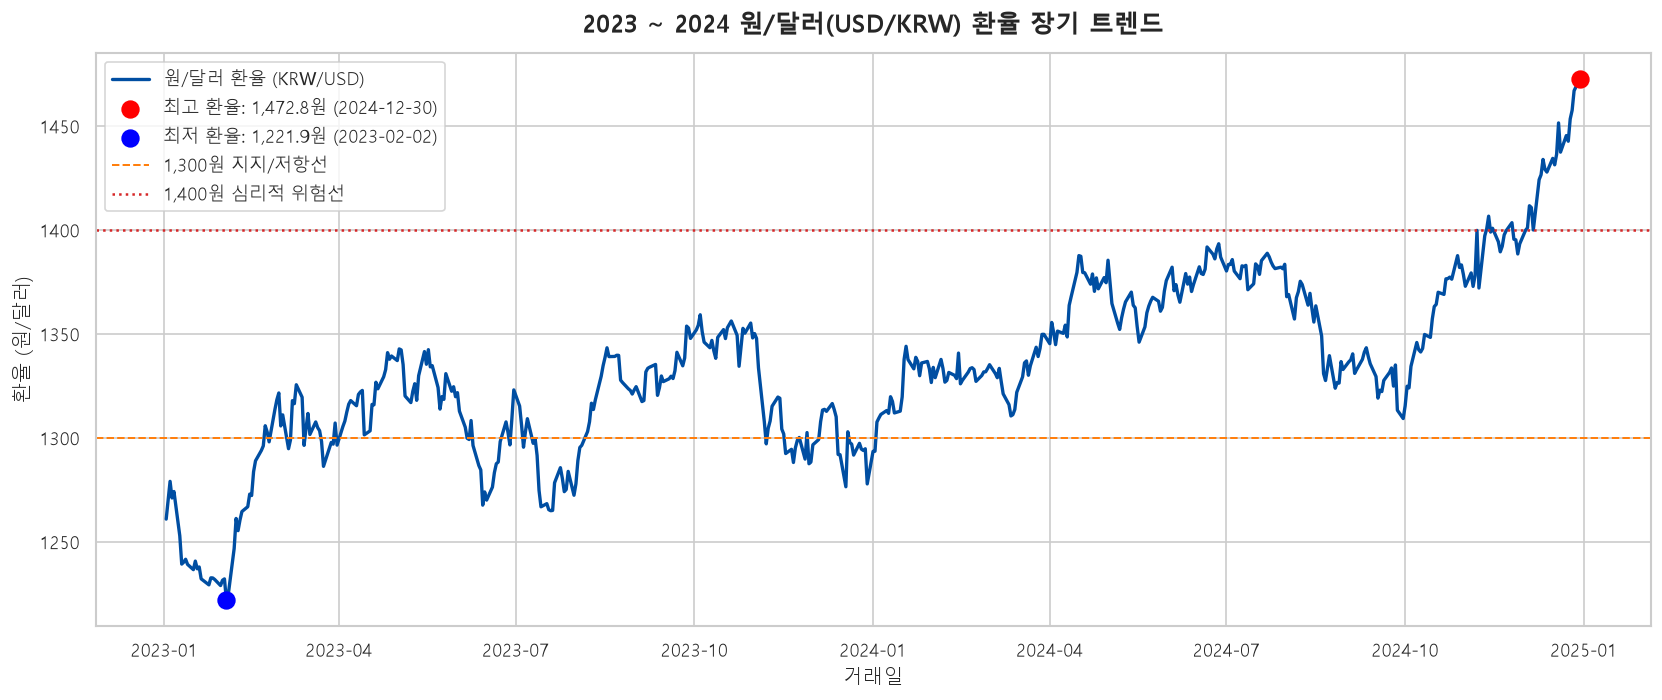

In [4]:
# STEP 3: 차트 1 - 2개년 환율 트렌드 및 1,300원/1,400원 마디선
plt.figure(figsize=(14, 6))
plt.plot(df.index, df["Close"], label="원/달러 환율 (KRW/USD)", color="#004ea2", linewidth=2)
max_p, max_d = df["Close"].max(), df["Close"].idxmax()
min_p, min_d = df["Close"].min(), df["Close"].idxmin()
plt.scatter([max_d], [max_p], color="red", s=100, zorder=5, label=f"최고 환율: {max_p:,.1f}원 ({max_d.strftime('%Y-%m-%d')})")
plt.scatter([min_d], [min_p], color="blue", s=100, zorder=5, label=f"최저 환율: {min_p:,.1f}원 ({min_d.strftime('%Y-%m-%d')})")
plt.axhline(1300, color="#ff7f0e", linestyle="--", linewidth=1.2, label="1,300원 지지/저항선")
plt.axhline(1400, color="#d62728", linestyle=":", linewidth=1.5, label="1,400원 심리적 위험선")
plt.title("2023 ~ 2024 원/달러(USD/KRW) 환율 장기 트렌드", fontsize=15, fontweight="bold", pad=12)
plt.xlabel("거래일"); plt.ylabel("환율 (원/달러)"); plt.legend(loc="upper left"); plt.tight_layout()
plt.savefig("images/01_exchange_rate_trend.png", dpi=300)
plt.show()

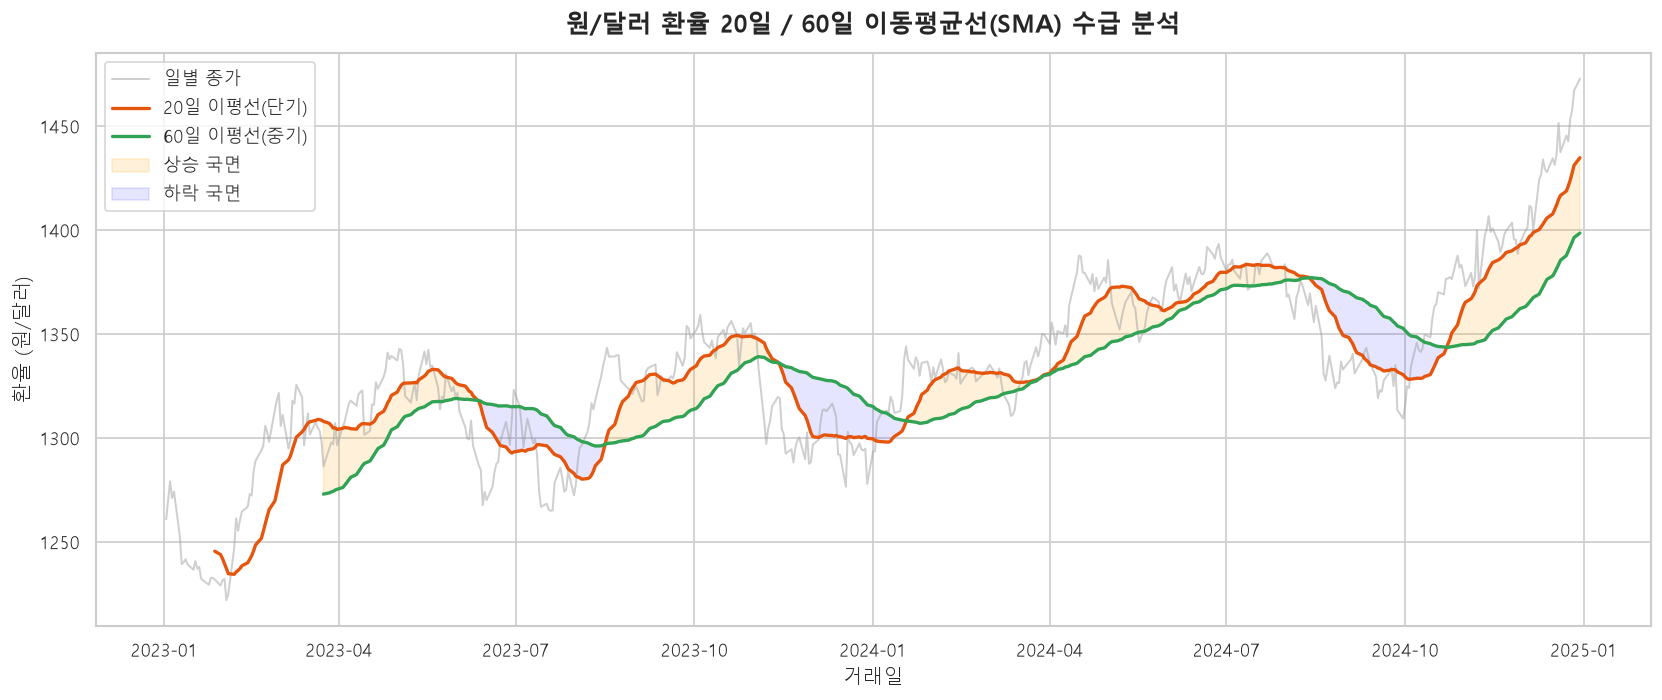

In [5]:
# STEP 4: 차트 2 - 20일 / 60일 이동평균선 수급 분석
plt.figure(figsize=(14, 6))
plt.plot(df.index, df["Close"], label="일별 종가", color="#a0a0a0", alpha=0.5, linewidth=1.2)
plt.plot(df.index, df["SMA_20"], label="20일 이평선(단기)", color="#e6550d", linewidth=2.0)
plt.plot(df.index, df["SMA_60"], label="60일 이평선(중기)", color="#31a354", linewidth=2.0)
plt.fill_between(df.index, df["SMA_20"], df["SMA_60"], where=(df["SMA_20"] >= df["SMA_60"]), color="orange", alpha=0.15, label="상승 국면")
plt.fill_between(df.index, df["SMA_20"], df["SMA_60"], where=(df["SMA_20"] < df["SMA_60"]), color="blue", alpha=0.1, label="하락 국면")
plt.title("원/달러 환율 20일 / 60일 이동평균선(SMA) 수급 분석", fontsize=15, fontweight="bold", pad=12)
plt.xlabel("거래일"); plt.ylabel("환율 (원/달러)"); plt.legend(loc="upper left"); plt.tight_layout()
plt.savefig("images/02_moving_average.png", dpi=300)
plt.show()

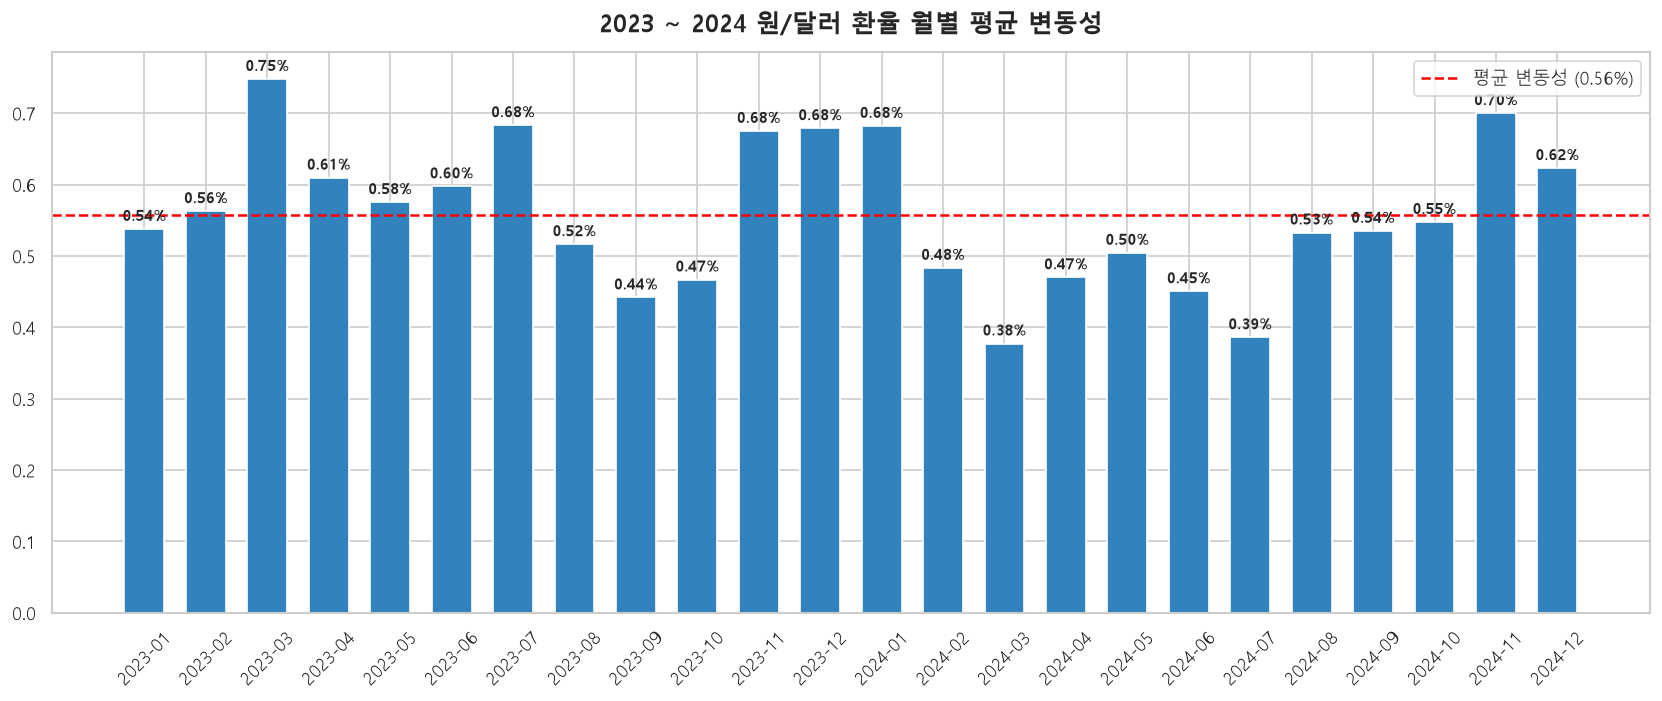

In [6]:
# STEP 5: 차트 3 - 월별 평균 변동성 (표준편차)
monthly_vol = df.groupby(df["Year_Month"])["Volatility_20"].mean().dropna()
plt.figure(figsize=(14, 6))
bars = plt.bar([str(ym) for ym in monthly_vol.index], monthly_vol.values, color="#3182bd", width=0.65)
plt.axhline(monthly_vol.mean(), color="red", linestyle="--", label=f"평균 변동성 ({monthly_vol.mean():.2f}%)")
for bar in bars:
    h = bar.get_height()
    plt.annotate(f"{h:.2f}%", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
plt.title("2023 ~ 2024 원/달러 환율 월별 평균 변동성", fontsize=15, fontweight="bold", pad=12)
plt.xticks(rotation=45); plt.legend(loc="upper right"); plt.tight_layout()
plt.savefig("images/03_monthly_volatility.png", dpi=300)
plt.show()

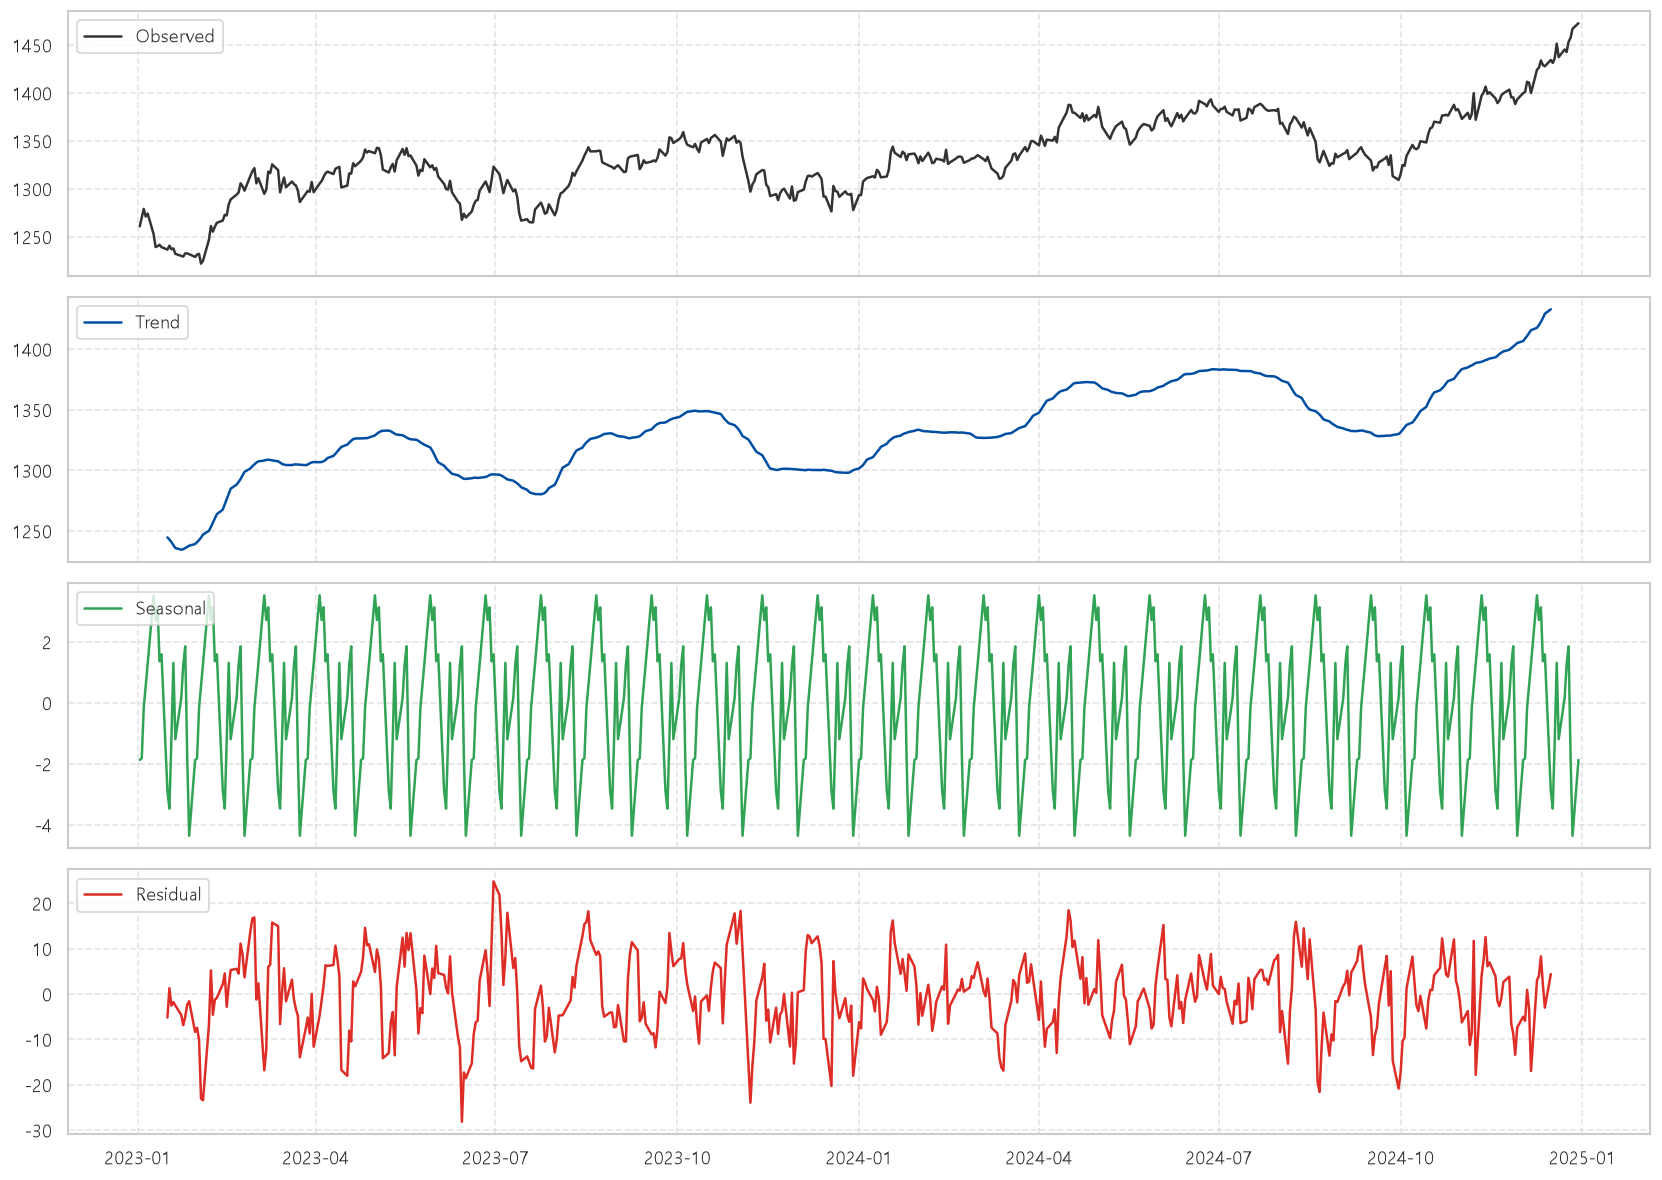

In [7]:
# STEP 6: 차트 4 - [심화 A] 시계열 가법 분해
decomp = seasonal_decompose(df["Close"].dropna(), model="additive", period=20)
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
axes[0].plot(decomp.observed, color="#333333", label="Observed")
axes[1].plot(decomp.trend, color="#004ea2", label="Trend")
axes[2].plot(decomp.seasonal, color="#31a354", label="Seasonal")
axes[3].plot(decomp.resid, color="#de2d26", label="Residual")
for ax in axes: ax.legend(loc="upper left"); ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("images/04_seasonal_decompose.png", dpi=300)
plt.show()

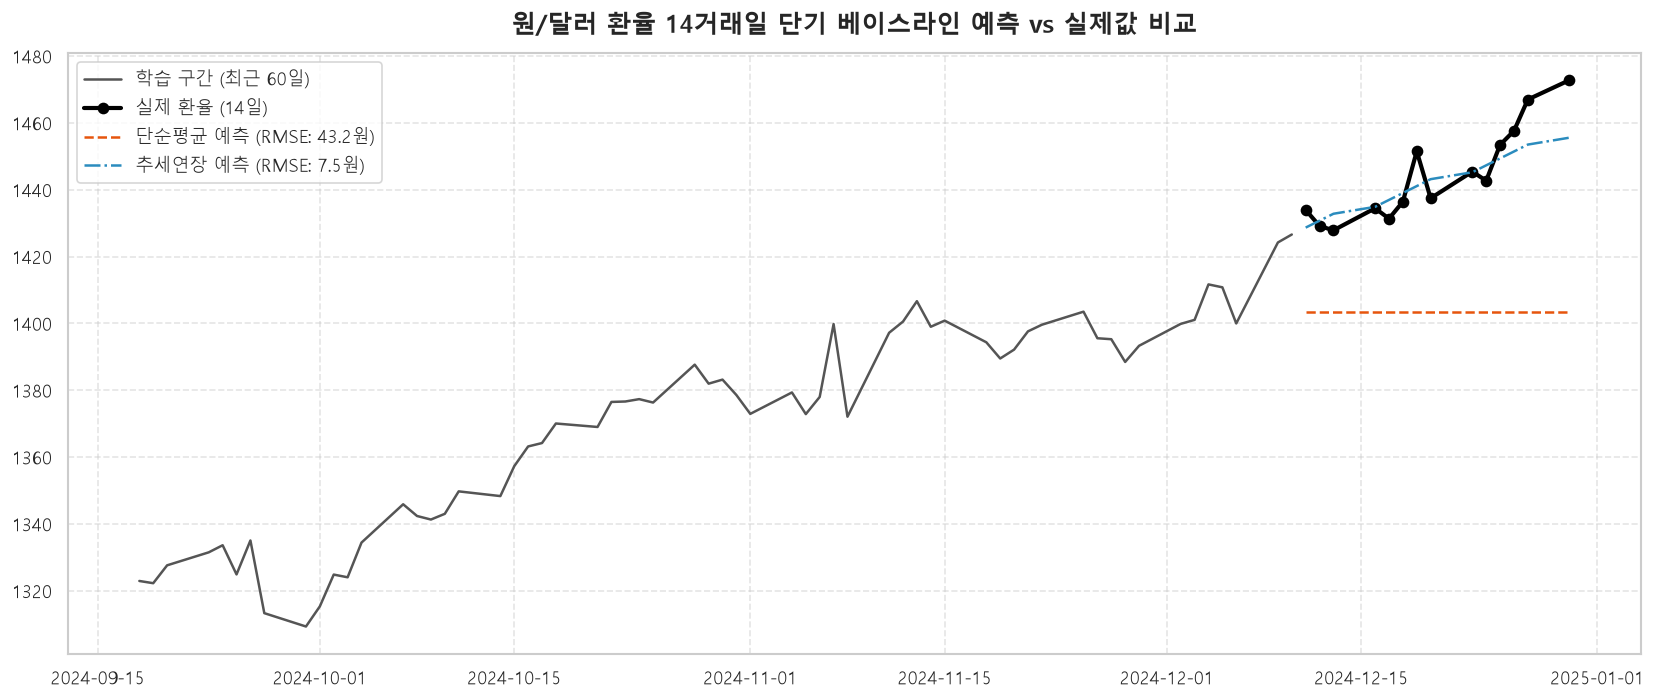

In [8]:
# STEP 7: 차트 5 - [심화 B] 14거래일 단기 베이스라인 예측
test_days = 14
train = df["Close"].iloc[:-test_days]
test = df["Close"].iloc[-test_days:]
sma_preds = pd.Series(train.iloc[-14:].mean(), index=test.index)
drift_slope = (train.iloc[-1] - train.iloc[-14]) / 14
drift_preds = pd.Series([train.iloc[-1] + drift_slope * (i + 1) for i in range(test_days)], index=test.index)
rmse_sma = np.sqrt(np.mean((test - sma_preds)**2))
rmse_drift = np.sqrt(np.mean((test - drift_preds)**2))
plt.figure(figsize=(14, 6))
plt.plot(train.iloc[-60:].index, train.iloc[-60:], label="학습 구간 (최근 60일)", color="#555555")
plt.plot(test.index, test, label="실제 환율 (14일)", color="black", linewidth=2.5, marker="o")
plt.plot(test.index, sma_preds, label=f"단순평균 예측 (RMSE: {rmse_sma:,.1f}원)", color="#e6550d", linestyle="--")
plt.plot(test.index, drift_preds, label=f"추세연장 예측 (RMSE: {rmse_drift:,.1f}원)", color="#2b8cbe", linestyle="-.")
plt.title("원/달러 환율 14거래일 단기 베이스라인 예측 vs 실제값 비교", fontsize=15, fontweight="bold", pad=12)
plt.legend(); plt.grid(True, linestyle="--", alpha=0.5); plt.tight_layout()
plt.savefig("images/05_baseline_forecast.png", dpi=300)
plt.show()